# Notebook 35 — Exact coverage, market regimes and paired trading signals

**Research question:** Does chronological OOF stacking select higher-quality Up trades than full-history RF when all models are forced to select the **same number of validation observations**?

**Inputs:** Notebook 34's saved *development-fold* validation predictions. No retraining or historical final-holdout access. The retrospective exact top-k rule uses the entire validation score distribution; **this is a ranking diagnostic, not a live trading policy**. Trading results are indicative, not realized P&L. We use raw probabilities; Platt calibration in Notebook 34 preserved rankings.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if not (ROOT/'src').exists(): raise FileNotFoundError('Open this notebook inside stock_ml_dynamic')
sys.path.insert(0,str(ROOT/'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from stock_ml_dynamic.exact_coverage_regime_research import run_research, load_predictions
INPUT=ROOT/'artifacts/notebook34_calibration_coverage/validation_predictions.parquet'
OUTPUT=ROOT/'artifacts/notebook35_exact_coverage_regimes'
COVERAGES=(.05,.10,.15,.20,.25)
BOOTSTRAP_REPS=1000
SEED=42
print('Input:',INPUT,'exists:',INPUT.exists())

Input: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook34_calibration_coverage/validation_predictions.parquet exists: True


## 1. Load saved out-of-sample predictions from Notebook 34

No models are fitted in Notebook 35. If this file is absent, run Notebook 34 and ensure its outputs were written to the repository-root `artifacts/` directory.

In [2]:
preds=load_predictions(INPUT)
print('Rows:',len(preds),'Folds:',sorted(preds.fold.unique()),'Models:',sorted(preds.model.unique()))
print('Date range:',preds.bar_timestamp.min(),preds.bar_timestamp.max())
print('Unique symbols:',preds.symbol.nunique())
display(preds.groupby(['fold','model','calibration']).size().unstack(['model','calibration']))

Rows: 935004 Folds: [np.int64(1), np.int64(2), np.int64(3)] Models: ['full_history_rf', 'oof_meta_logistic', 'oof_meta_rf']
Date range: 2022-05-27 00:00:00+00:00 2025-04-08 00:00:00+00:00
Unique symbols: 219


model       full_history_rf        oof_meta_logistic        oof_meta_rf       
calibration           platt    raw             platt    raw       platt    raw
fold                                                                          
1                     51646  51646             51646  51646       51646  51646
2                     51863  51863             51863  51863       51863  51863
3                     52325  52325             52325  52325       52325  52325

## 2. Exact top-k and paired selection comparisons

For each outer fold, every model selects exactly `round(coverage × number of validation rows)` observations. Rankings are computed retrospectively on the validation fold. The same labels and returns are used for each model, and all model prediction keys must align.

In [3]:
result=run_research(INPUT,output_dir=OUTPUT,coverages=COVERAGES,reps=BOOTSTRAP_REPS,seed=SEED)
scores=result['exact_scores']; paired=result['paired']; boot=result['bootstrap']; regimes=result['regimes']; regime_scores=result['regime_scores']
assert scores.groupby(['fold','target_coverage']).k.nunique().eq(1).all()
assert scores.groupby(['fold','target_coverage']).entries.nunique().eq(1).all()
print('Policy rows:',len(scores),'Paired selection rows:',len(paired),'Bootstrap rows:',len(boot))
display(scores.groupby(['target_coverage','model'])[['up_precision','mean_net','actual_coverage']].mean().round(5))

Policy rows: 45 Paired selection rows: 90 Bootstrap rows: 60


up_precision  mean_net  actual_coverage
target_coverage model                                                     
0.05            full_history_rf         0.46664   0.00065             0.05
                oof_meta_logistic       0.47270   0.00073             0.05
                oof_meta_rf             0.46883   0.00071             0.05
0.10            full_history_rf         0.46223   0.00043             0.10
                oof_meta_logistic       0.46827   0.00082             0.10
                oof_meta_rf             0.46123   0.00021             0.10
0.15            full_history_rf         0.45681   0.00046             0.15
                oof_meta_logistic       0.46140   0.00063             0.15
                oof_meta_rf             0.45965   0.00037             0.15
0.20            full_history_rf         0.45286   0.00033             0.20
                oof_meta_logistic       0.45844   0.00043             0.20
                oof_meta_rf             0.45788   0.00038             0.20
0.25            full_history_rf         0.45159   0.00029             0.25
                oof_meta_logistic       0.45480   0.00036             0.25
                oof_meta_rf             0.45315   0.00027             0.25

## 3. Paired fold-by-fold differences vs full-history RF

In [4]:
baseline=scores.loc[scores.model.eq('full_history_rf')].set_index(['fold','target_coverage'])
comparisons=[]
for model in ['oof_meta_logistic','oof_meta_rf']:
    for _,row in scores[scores.model.eq(model)].iterrows():
        b=baseline.loc[(row.fold,row.target_coverage)]
        comparisons.append({'fold':row.fold,'coverage':row.target_coverage,'model':model,
                            'delta_up_precision_pp':100*(row.up_precision-b.up_precision),
                            'delta_net_bps':10000*(row.mean_net-b.mean_net)})
comparisons=pd.DataFrame(comparisons)
display(comparisons.round(4))
display(comparisons.groupby(['coverage','model'])[['delta_up_precision_pp','delta_net_bps']].mean().round(4))

,fold,coverage,model,delta_up_precision_pp,delta_net_bps
0,1,0.05,oof_meta_logistic,1.1232,3.5743
1,1,0.10,oof_meta_logistic,0.7357,3.9270
2,1,0.15,oof_meta_logistic,0.3356,1.3694
3,1,0.20,oof_meta_logistic,0.8810,3.5730
4,1,0.25,oof_meta_logistic,0.5499,2.1056
5,2,0.05,oof_meta_logistic,0.7327,4.4323
6,2,0.10,oof_meta_logistic,0.6556,7.9893
7,2,0.15,oof_meta_logistic,0.9384,6.6223
8,2,0.20,oof_meta_logistic,1.1279,5.9063
9,2,0.25,oof_meta_logistic,0.7790,5.6553


delta_up_precision_pp  delta_net_bps
coverage model                                                  
0.05     oof_meta_logistic                 0.6059         0.7430
         oof_meta_rf                       0.2191         0.5196
0.10     oof_meta_logistic                 0.6039         3.8673
         oof_meta_rf                      -0.0994        -2.2337
0.15     oof_meta_logistic                 0.4587         1.6927
         oof_meta_rf                       0.2841        -0.8954
0.20     oof_meta_logistic                 0.5582         0.9508
         oof_meta_rf                       0.5014         0.4798
0.25     oof_meta_logistic                 0.3206         0.7307
         oof_meta_rf                       0.1562        -0.1475

## 4. Shared vs unique trades

The `shared` bucket contains trades selected by both models. `baseline_only` and `challenger_only` have equal counts by construction; differences in their average returns directly explain the ranking advantage or disadvantage.

entries  up_precision  \
target_coverage challenger        selection                                   
0.05            oof_meta_logistic baseline_only     711.00000       0.43932   
                                  challenger_only   711.00000       0.47566   
                                  shared           1886.00000       0.47973   
                oof_meta_rf       baseline_only     742.00000       0.44377   
                                  challenger_only   742.00000       0.43107   
                                  shared           1855.00000       0.48038   
0.10            oof_meta_logistic baseline_only    1405.00000       0.42978   
                                  challenger_only  1405.00000       0.46110   
                                  shared           3789.33333       0.47121   
                oof_meta_rf       baseline_only    1736.00000       0.45131   
                                  challenger_only  1736.00000       0.44436   
                                  shared           3458.33333       0.46871   
0.15            oof_meta_logistic baseline_only    2049.66667       0.42718   
                                  challenger_only  2049.66667       0.44488   
                                  shared           5742.00000       0.46672   
                oof_meta_rf       baseline_only    2410.00000       0.44204   
                                  challenger_only  2410.00000       0.45102   
                                  shared           5381.66667       0.46392   
0.20            oof_meta_logistic baseline_only    2608.33333       0.41694   
                                  challenger_only  2608.33333       0.44272   
                                  shared           7780.66667       0.46399   
                oof_meta_rf       baseline_only    3094.00000       0.43204   
                                  challenger_only  3094.00000       0.44572   
                                  shared           7295.00000       0.46228   
0.25            oof_meta_logistic baseline_only    3037.00000       0.42077   
                                  challenger_only  3037.00000       0.43510   
                                  shared           9949.33333       0.46098   
                oof_meta_rf       baseline_only    4053.00000       0.43016   
                                  challenger_only  4053.00000       0.43416   
                                  shared           8933.33333       0.46067   

                                                   mean_net  
target_coverage challenger        selection                  
0.05            oof_meta_logistic baseline_only    -0.00046  
                                  challenger_only   0.00001  
                                  shared            0.00124  
                oof_meta_rf       baseline_only     0.00030  
                                  challenger_only   0.00013  
                                  shared            0.00142  
0.10            oof_meta_logistic baseline_only    -0.00044  
                                  challenger_only   0.00124  
                                  shared            0.00073  
                oof_meta_rf       baseline_only     0.00079  
                                  challenger_only  -0.00017  
                                  shared            0.00035  
0.15            oof_meta_logistic baseline_only    -0.00043  
                                  challenger_only   0.00010  
                                  shared            0.00074  
                oof_meta_rf       baseline_only     0.00062  
                                  challenger_only   0.00004  
                                  shared            0.00042  
0.20            oof_meta_logistic baseline_only    -0.00075  
                                  challenger_only  -0.00029  
                                  shared            0.00065  
                oof_meta_rf       baseline_only     0.00021  
                                  cha

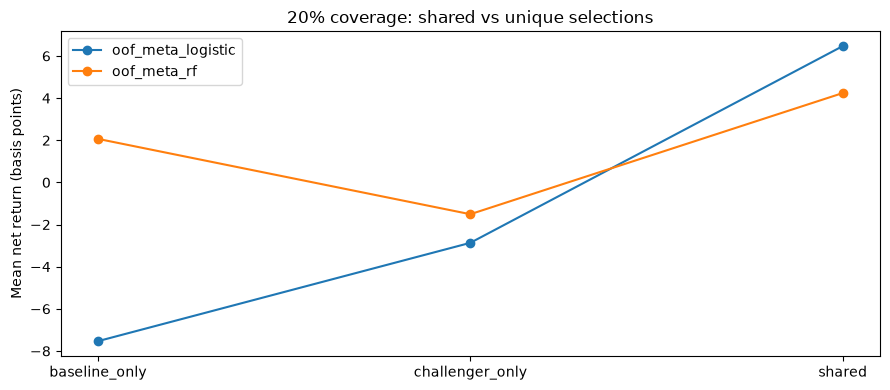

In [5]:
display(paired.groupby(['target_coverage','challenger','selection'])[['entries','up_precision','mean_net']].mean().round(5))
subset=paired.loc[paired.target_coverage.eq(.20)]
fig,ax=plt.subplots(figsize=(9,4))
for model,g in subset.groupby('challenger'):
    values=g.groupby('selection').mean_net.mean()
    ax.plot(values.index,values.values*10000,marker='o',label=model)
ax.set_ylabel('Mean net return (basis points)');ax.set_title('20% coverage: shared vs unique selections')
ax.legend();plt.tight_layout();plt.show()

## 5. Historical market-regime diagnostics

Regime proxy: cross-sectional mean next-bar return, lagged **two dates** before its use. Bull/bear is the sign of the trailing 20-day mean; high/low volatility compares the trailing 20-day volatility with a prior-only 60-day rolling median. This is a *validation-period descriptive proxy*, not a trained regime classifier. Warm-up dates with insufficient history are excluded.

In [6]:
print('Regime-eligible dates:',regimes.dropna(subset=['trend_regime','vol_regime']).shape[0], 'of',len(regimes))
display(regime_scores.groupby(['target_coverage','model','regime_type','regime'])[['entries','up_precision','mean_net']].mean().round(5))
for coverage in [.10,.20]:
    sub=regime_scores[(regime_scores.target_coverage==coverage)&(regime_scores.regime_type=='trend_regime')]
    pivot=sub.groupby(['model','regime']).mean_net.mean().unstack()
    display(pivot.rename_axis(index='Model').round(5))

Regime-eligible dates: 593 of 716


entries  \
target_coverage model             regime_type  regime                 
0.05            full_history_rf   trend_regime bearish   1566.00000   
                                               bullish    723.66667   
                                  vol_regime   high_vol  1558.66667   
                                               low_vol    608.33333   
                oof_meta_logistic trend_regime bearish   1361.00000   
                                               bullish    886.33333   
                                  vol_regime   high_vol  1444.33333   
                                               low_vol    690.00000   
                oof_meta_rf       trend_regime bearish   1322.00000   
                                               bullish    949.66667   
                                  vol_regime   high_vol  1407.33333   
                                               low_vol    752.33333   
0.10            full_history_rf   trend_regime bearish   2810.66667   
                                               bullish   1804.00000   
                                  vol_regime   high_vol  2867.00000   
                                               low_vol   1467.33333   
                oof_meta_logistic trend_regime bearish   2496.66667   
                                               bullish   2036.33333   
                                  vol_regime   high_vol  2701.00000   
                                               low_vol   1542.33333   
                oof_meta_rf       trend_regime bearish   2314.33333   
                                               bullish   2166.00000   
                                  vol_regime   high_vol  2531.66667   
                                               low_vol   1613.00000   
0.15            full_history_rf   trend_regime bearish   3851.00000   
                                               bullish   3092.66667   
                                  vol_regime   high_vol  4040.00000   
                                               low_vol   2431.00000   
                oof_meta_logistic trend_regime bearish   3502.33333   
                                               bullish   3340.33333   
                                  vol_regime   high_vol  3860.00000   
                                               low_vol   2494.00000   
                oof_meta_rf       trend_regime bearish   3277.00000   
                                               bullish   3503.33333   
                                  vol_regime   high_vol  3695.66667   
                                               low_vol   2539.66667   
0.20            full_history_rf   trend_regime bearish   4792.66667   
                                               bullish   4515.33333   
                                  vol_regime   high_vol  5137.00000   
                                               low_vol   3472.66667   
                oof_meta_logistic trend_regime bearish   4406.00000   
                                               bullish   4778.66667   
                                  vol_regime   high_vol  5007.00000   
                                               low_vol   3483.33333   
                oof_meta_rf       trend_regime bearish   4182.33333   
                                               bullish   4960.00000   
                                  vol_regime   high_vol  4865.33333   
                                               low_vol   3524.66667   
0.25            full_history_rf   trend_regime bearish   5638.66667   
                                               bullish   6033.33333   
                                  vol_regime   high_vol  6218.00000   
                                               low_vol   4517.66667   
                oof_meta_logistic trend_regime bearish   5241.66667   
                                               bullish   6308.33333   
                                  vol_regime   high_vol  6131.00000   
             

regime,bearish,bullish
Model,,
full_history_rf,0.00160,0.00119
oof_meta_logistic,0.00167,0.00146
oof_meta_rf,0.00125,0.00059


regime,bearish,bullish
Model,,
full_history_rf,0.00070,0.00100
oof_meta_logistic,0.00061,0.00101
oof_meta_rf,0.00063,0.00076


## 6. Date-block bootstrap confidence intervals

Resample entire trading dates **within each outer fold**, retaining all stocks and paired model predictions on each sampled date. The intervals describe uncertainty conditional on this historical design; they do not establish a deployable edge. Multiple coverage/model comparisons are exploratory.

In [7]:
view=boot.copy()
for field in ['point_estimate','ci_low','ci_high']:
    view[field]=view[field]*100
print('Precision differences in percentage points; return differences in percentage points')
display(view[view.target_coverage.isin([.10,.20,.25])].round(4))
print('Intervals excluding zero by metric:')
display(boot.assign(excludes_zero=(boot.ci_low>0)|(boot.ci_high<0)).groupby(['challenger','metric']).excludes_zero.agg(['sum','count']))

Precision differences in percentage points; return differences in percentage points


,fold,target_coverage,challenger,metric,point_estimate,ci_low,ci_high,days,bootstrap_reps
4,1,0.10,oof_meta_logistic,up_precision_difference,0.7357,-0.8201,2.2109,218,1000
5,1,0.10,oof_meta_logistic,mean_net_difference,0.0393,-0.0357,0.1209,218,1000
6,1,0.10,oof_meta_rf,up_precision_difference,-1.4327,-4.4865,1.5299,218,1000
7,1,0.10,oof_meta_rf,mean_net_difference,-0.0784,-0.2603,0.1032,218,1000
12,1,0.20,oof_meta_logistic,up_precision_difference,0.8810,-0.5347,2.5052,235,1000
13,1,0.20,oof_meta_logistic,mean_net_difference,0.0357,-0.0322,0.1099,235,1000
14,1,0.20,oof_meta_rf,up_precision_difference,0.1549,-3.0110,3.1398,235,1000
15,1,0.20,oof_meta_rf,mean_net_difference,-0.0079,-0.1516,0.1322,235,1000
16,1,0.25,oof_meta_logistic,up_precision_difference,0.5499,-0.6994,1.8880,237,1000
17,1,0.25,oof_meta_logistic,mean_net_difference,0.0211,-0.0321,0.0818,237,1000


Intervals excluding zero by metric:


sum  count
challenger        metric                             
oof_meta_logistic mean_net_difference        1     15
                  up_precision_difference    0     15
oof_meta_rf       mean_net_difference        0     15
                  up_precision_difference    0     15

## 7. Interpret and decide

- Prefer comparisons with the same **exact k** in each fold; check the paired confidence intervals and differences across folds.
- Compare unique trades, not just shared trades.
- Look for improvements that persist across market regimes and coverage settings.
- **Do not** use validation-wide top-k selection as a deployable strategy. Live thresholds must be learned from earlier data and applied prospectively.
- Historical final holdout remains closed. Prospective ledger is untouched.

In [8]:
print('Saved research tables to:',OUTPUT)
print('No training performed. Closed final historical holdout and prospective ledger were not accessed.')

Saved research tables to: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook35_exact_coverage_regimes
No training performed. Closed final historical holdout and prospective ledger were not accessed.
